# Improved VEPL-Net Vegetation Segmentation Training

This notebook contains optimized training for the VEPL vegetation segmentation model with the following improvements:

1. **Learning Rate Scheduler**: ReduceLROnPlateau for adaptive learning rate
2. **Combined Loss Function**: Dice Loss + BCE Loss for better segmentation performance
3. **Early Stopping**: Prevents overfitting and saves computation time
4. **Enhanced Data Augmentation**: More robust augmentations for aerial imagery
5. **Modern Encoder**: EfficientNet-B4 instead of VGG16 for better performance
6. **Weight Decay Regularization**: L2 regularization to prevent overfitting

## 1. Import Required Libraries

In [1]:
import os
import cv2
import torch
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import ReduceLROnPlateau
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully")
print(f"PyTorch version: {torch.__version__}")
print(f"Segmentation Models PyTorch version: {smp.__version__}")

All libraries imported successfully
PyTorch version: 2.7.1
Segmentation Models PyTorch version: 0.5.0


## 2. Configuration and Hyperparameters

In [2]:
# =============================================================================
# DEVICE CONFIGURATION
# =============================================================================
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using device: {DEVICE}")

# MPS-specific settings
if DEVICE == "mps":
    # Enable optimizations for MPS
    torch.backends.mps.allow_tf32 = True
    print("MPS optimizations enabled")

# =============================================================================
# DATA PATHS
# =============================================================================
PROCESSED_IMG_DIR = '../processed_data/images'
PROCESSED_MSK_DIR = '../processed_data/masks'
MODEL_SAVE_DIR = '../models'
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

# =============================================================================
# DATASET CLASS VALUES
# =============================================================================
VEGETATION_CHANNEL = 1  # Green channel for vegetation detection
VEGETATION_PIXEL_VAL = 255

# =============================================================================
# SHARED TRAINING HYPERPARAMETERS
# =============================================================================
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 256
TRAIN_TEST_SPLIT_RATIO = 0.2
RANDOM_SEED = 42

# =============================================================================
# MPS-OPTIMIZED VEGETATION MODEL CONFIGURATION
# =============================================================================
VEG_ENCODER = "vgg16"  # Good performance on MPS
VEG_ARCHITECTURE = "Unet"

# MPS-optimized batch sizes and settings
VEG_BATCH_SIZE = 16  # Reduced for MPS memory efficiency
VEG_NUM_EPOCHS = 5
VEG_LEARNING_RATE = 0.00001
VEG_WEIGHT_DECAY = 0
print("Using MPS-optimized settings")

print(f"\nVegetation Model Configuration:")
print(f"{VEG_ARCHITECTURE}+{VEG_ENCODER}, Batch={VEG_BATCH_SIZE}, Max Epochs={VEG_NUM_EPOCHS}")
print(f"Initial LR={VEG_LEARNING_RATE}, Weight Decay={VEG_WEIGHT_DECAY}")

Using device: mps
MPS optimizations enabled
Using MPS-optimized settings

Vegetation Model Configuration:
Unet+vgg16, Batch=16, Max Epochs=5
Initial LR=1e-05, Weight Decay=0


## 3. Combined Loss Function (Dice + BCE)

In [3]:
# class CombinedLoss(nn.Module):
#     """
#     Combined loss function that combines Dice Loss and BCE Loss.
#     This balances pixel-wise accuracy (BCE) with region-based accuracy (Dice).
#     """
#     def __init__(self, dice_weight=0.5, bce_weight=0.5):
#         super(CombinedLoss, self).__init__()
#         self.dice_weight = dice_weight
#         self.bce_weight = bce_weight
#         self.bce_loss = nn.BCEWithLogitsLoss()
#         self.dice_loss = smp.losses.DiceLoss(mode='binary', from_logits=True)
        
#     def forward(self, predictions, targets):
#         bce = self.bce_loss(predictions, targets)
#         dice = self.dice_loss(predictions, targets)
#         return self.bce_weight * bce + self.dice_weight * dice

# print("CombinedLoss (Dice + BCE) class defined successfully")
# print("This loss function balances pixel-wise accuracy with region-based accuracy")

## 4. Early Stopping Class

In [4]:
# class EarlyStopping:
#     """
#     Early stopping to terminate training when validation IoU stops improving.
#     """
#     def __init__(self, patience=15, min_delta=0, restore_best_weights=True):
#         self.patience = patience
#         self.min_delta = min_delta
#         self.restore_best_weights = restore_best_weights
#         self.best_score = None
#         self.counter = 0
#         self.best_weights = None
#         self.early_stop = False
        
#     def __call__(self, val_score, model):
#         if self.best_score is None:
#             self.best_score = val_score
#             self.save_checkpoint(model)
#         elif val_score < self.best_score + self.min_delta:
#             self.counter += 1
#             if self.counter >= self.patience:
#                 self.early_stop = True
#                 if self.restore_best_weights:
#                     model.load_state_dict(self.best_weights)
#         else:
#             self.best_score = val_score
#             self.save_checkpoint(model)
#             self.counter = 0
            
#     def save_checkpoint(self, model):
#         """Save model when validation score improves."""
#         self.best_weights = model.state_dict().copy()

# print("EarlyStopping class defined successfully")
# print(f"Will stop training if no improvement for {EARLY_STOPPING_PATIENCE} epochs")

## 5. Custom Dataset Class for Vegetation Segmentation

In [5]:
class VEPLVegetationDataset(Dataset):
    """
    Custom Dataset class for VEPL vegetation segmentation.
    Converts multi-class masks to binary vegetation masks.
    """
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]
        
        # Load RGB image and convert from BGR to RGB
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # Load mask without any color space conversion
        mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
        
        # Create binary mask for vegetation (green pixels)
        binary_mask = (mask[:, :, VEGETATION_CHANNEL] == VEGETATION_PIXEL_VAL).astype(np.float32)
        binary_mask = np.expand_dims(binary_mask, axis=-1)

        # Apply transformations if provided
        if self.transform:
            augmented = self.transform(image=image, mask=binary_mask)
            image = augmented['image']
            binary_mask = augmented['mask']
            binary_mask = binary_mask.permute(2, 0, 1)

        return image, binary_mask

print("VEPLVegetationDataset class defined successfully")

VEPLVegetationDataset class defined successfully


## 6. Training and Evaluation Functions

In [6]:
def train_fn(loader, model, optimizer, loss_fn, scaler=None):
    """
    MPS-compatible training function for one epoch.
    """
    model.train()
    loop = tqdm(loader, desc="Training Vegetation Model")
    total_loss = 0.0
    num_batches = len(loader)
    
    # Device-specific AMP settings
    use_amp = (DEVICE == "cuda")  # Only use AMP on CUDA
    
    for batch_idx, (data, targets) in enumerate(loop):
        data = data.to(device=DEVICE, non_blocking=True)
        targets = targets.float().to(device=DEVICE, non_blocking=True)
        
        # Skip batches that are too small for BatchNorm
        if data.size(0) < 2:
            print(f"Skipping batch {batch_idx} with size {data.size(0)}")
            continue

        # Forward pass with device-specific AMP
        if use_amp and scaler is not None:
            with torch.autocast(device_type="cuda", enabled=True):
                predictions = model(data)
                loss = loss_fn(predictions, targets)
        else:
            # No AMP for MPS/CPU
            predictions = model(data)
            loss = loss_fn(predictions, targets)
        
        total_loss += loss.item()

        # Backward pass with device-specific handling
        optimizer.zero_grad()
        
        if use_amp and scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        
        # MPS memory management
        if DEVICE == "mps" and batch_idx % 10 == 0:  # Clear cache every 10 batches
            torch.mps.empty_cache()

        loop.set_postfix({
            'loss': f'{loss.item():.4f}',
            'avg_loss': f'{total_loss/(batch_idx+1):.4f}'
        })
        
    return total_loss / num_batches


def check_accuracy(loader, model, device):
    """
    MPS-compatible evaluation function.
    """
    model.eval()
    num_correct = 0
    num_pixels = 0
    dice_score = 0
    iou_score = 0
    num_batches = len(loader)

    with torch.no_grad():
        for batch_idx, (x, y) in enumerate(loader):
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            
            if x.size(0) < 1:
                continue
            
            preds = torch.sigmoid(model(x))
            preds = (preds > 0.5).float()
            
            num_correct += (preds == y).sum()
            num_pixels += torch.numel(preds)
            
            tp, fp, fn, tn = smp.metrics.get_stats(preds.long(), y.long(), mode='binary')
            iou_score += smp.metrics.iou_score(tp, fp, fn, tn, reduction="micro")
            dice_score += smp.metrics.f1_score(tp, fp, fn, tn, reduction="micro")
            
            # MPS memory management during evaluation
            if DEVICE == "mps" and batch_idx % 5 == 0:
                torch.mps.empty_cache()

    iou = iou_score / num_batches
    dice = dice_score / num_batches
    acc = num_correct / num_pixels * 100
    
    print(f"Validation: IoU Score: {iou:.4f} | Dice Score: {dice:.4f} | Pixel Accuracy: {acc:.2f}%")

    model.train()
    return iou.item()

print("MPS-compatible training and evaluation functions defined successfully")

MPS-compatible training and evaluation functions defined successfully


## 7. Data Loading and Preparation

In [7]:
# Load all processed tile paths
print("Loading processed data...")

all_image_paths = sorted([os.path.join(PROCESSED_IMG_DIR, f) for f in os.listdir(PROCESSED_IMG_DIR) if f.endswith('.png')])
all_mask_paths = sorted([os.path.join(PROCESSED_MSK_DIR, f) for f in os.listdir(PROCESSED_MSK_DIR) if f.endswith('.png')])

print(f"Found {len(all_image_paths)} image tiles")
print(f"Found {len(all_mask_paths)} mask tiles")

assert len(all_image_paths) == len(all_mask_paths), f"Mismatch: {len(all_image_paths)} images vs {len(all_mask_paths)} masks"
print("Image and mask counts match")

# Split data (60% train, 20% validation, 20% test)
train_val_imgs, test_imgs, train_val_msks, test_msks = train_test_split(
    all_image_paths, all_mask_paths, 
    test_size=0.2, 
    random_state=RANDOM_SEED
)

train_imgs, val_imgs, train_msks, val_msks = train_test_split(
    train_val_imgs, train_val_msks,
    test_size=0.25,
    random_state=RANDOM_SEED
)

print(f"\nData split completed:")
print(f"Training samples: {len(train_imgs)} ({len(train_imgs)/len(all_image_paths)*100:.1f}%)")
print(f"Validation samples: {len(val_imgs)} ({len(val_imgs)/len(all_image_paths)*100:.1f}%)")
print(f"Test samples: {len(test_imgs)} ({len(test_imgs)/len(all_image_paths)*100:.1f}%)")

Loading processed data...
Found 22736 image tiles
Found 22736 mask tiles
Image and mask counts match

Data split completed:
Training samples: 13641 (60.0%)
Validation samples: 4547 (20.0%)
Test samples: 4548 (20.0%)


## 8. Enhanced Data Augmentation for Aerial Imagery

In [8]:
print("Defining enhanced data augmentation for aerial imagery...")

# Enhanced training augmentations with geometric and spectral transformations
train_transform = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    
    # Geometric augmentations - important for aerial imagery
    A.HorizontalFlip(p=0.5),
    # A.VerticalFlip(p=0.5),  # New: Vertical flip for aerial imagery
    # A.RandomRotate90(p=0.5),  # New: 90-degree rotations
    # A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=45, p=0.5),  # New: Complex geometric variations
    
    # Spectral augmentations - optimized for vegetation detection
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.3, hue=0.1, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
    
    # Additional augmentations for robustness
    # A.RandomGamma(gamma_limit=(80, 120), p=0.3),  # New: Gamma correction
    # A.GaussianBlur(blur_limit=3, p=0.2),  # New: Slight blur for noise robustness
    
    # Normalization and tensor conversion
    A.Normalize(mean=[0, 0, 0], std=[1, 1, 1], max_pixel_value=255.0),  # ImageNet normalization for EfficientNet
    ToTensorV2(),
])

# Validation transform (no augmentation)
val_transform = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    A.Normalize(mean=[0, 0, 0], std=[1, 1, 1], max_pixel_value=255.0),  # ImageNet normalization
    ToTensorV2(),
])

print("Enhanced augmentation strategy includes:")
print("- Geometric: Horizontal/Vertical flip, 90° rotations, ShiftScaleRotate")
print("- Spectral: ColorJitter, Brightness/Contrast, Gamma, Gaussian blur")
print("- Normalization: ImageNet stats for EfficientNet pretrained weights")

Defining enhanced data augmentation for aerial imagery...
Enhanced augmentation strategy includes:
- Geometric: Horizontal/Vertical flip, 90° rotations, ShiftScaleRotate
- Spectral: ColorJitter, Brightness/Contrast, Gamma, Gaussian blur
- Normalization: ImageNet stats for EfficientNet pretrained weights


## 9. Initialize Improved Vegetation Model with EfficientNet-B4

In [9]:
print("\n" + "="*70)
print("MPS-OPTIMIZED VEGETATION SEGMENTATION MODEL TRAINING")
print("="*70)

# Initialize vegetation model with device-optimized settings
print(f"Initializing {VEG_ARCHITECTURE} model with {VEG_ENCODER} encoder...")
model = smp.Unet(
    encoder_name=VEG_ENCODER,
    encoder_weights="imagenet",  # Pre-trained on ImageNet
    in_channels=3,
    classes=1,
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters: {total_params:,} total, {trainable_params:,} trainable")

# Initialize loss function and optimizer with device-specific settings
loss_fn = nn.BCEWithLogitsLoss()

# MPS-optimized optimizer settings
if DEVICE == "mps":
    optimizer = optim.AdamW(model.parameters(), lr=VEG_LEARNING_RATE, weight_decay=VEG_WEIGHT_DECAY)
    print("Using AdamW optimizer (better for MPS)")
else:
    optimizer = optim.Adam(model.parameters(), lr=VEG_LEARNING_RATE, weight_decay=VEG_WEIGHT_DECAY)
    print("Using Adam optimizer")

print(f"Learning Rate: {VEG_LEARNING_RATE}, Weight Decay: {VEG_WEIGHT_DECAY}")

# Add Learning Rate Scheduler
from torch.optim.lr_scheduler import ReduceLROnPlateau
scheduler = ReduceLROnPlateau(
    optimizer, 
    mode='max',  # Maximize IoU
    factor=0.25,  # Multiply LR by 0.5 when reducing
    patience=10,  # Wait 7 epochs before reducing
    min_lr=1e-6  # Minimum learning rate
)

print("Learning Rate Scheduler: ReduceLROnPlateau (patience=7, factor=0.5)")

# Initialize gradient scaler only for CUDA
scaler = None
if DEVICE == "cuda":
    scaler = torch.cuda.amp.GradScaler()
    print("CUDA AMP GradScaler initialized")
elif DEVICE == "mps":
    print("MPS: Using native precision (no AMP)")
else:
    print("CPU: Using native precision")

# Create MPS-optimized data loaders
print("\nCreating MPS-optimized data loaders...")

# MPS-specific DataLoader settings
num_workers = 0  # MPS works best with num_workers=0
pin_memory = False  # MPS doesn't benefit from pin_memory

train_loader = DataLoader(
    VEPLVegetationDataset(train_imgs, train_msks, transform=train_transform),
    batch_size=VEG_BATCH_SIZE, 
    shuffle=True, 
    num_workers=num_workers, 
    drop_last=True,
    pin_memory=pin_memory
)
val_loader = DataLoader(
    VEPLVegetationDataset(val_imgs, val_msks, transform=val_transform),
    batch_size=VEG_BATCH_SIZE, 
    shuffle=False, 
    num_workers=num_workers, 
    drop_last=False,
    pin_memory=pin_memory
)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

# MPS memory management
if DEVICE == "mps":
    torch.mps.empty_cache()
    print("MPS cache cleared and ready for training")

print(f"\nReady to train MPS-optimized vegetation model for up to {VEG_NUM_EPOCHS} epochs")
print("Training optimized for Apple Silicon MPS performance with LR scheduling")


MPS-OPTIMIZED VEGETATION SEGMENTATION MODEL TRAINING
Initializing Unet model with vgg16 encoder...
Model parameters: 23,748,241 total, 23,748,241 trainable
Using AdamW optimizer (better for MPS)
Learning Rate: 1e-05, Weight Decay: 0
Learning Rate Scheduler: ReduceLROnPlateau (patience=7, factor=0.5)
MPS: Using native precision (no AMP)

Creating MPS-optimized data loaders...
Training batches: 852
Validation batches: 285
MPS cache cleared and ready for training

Ready to train MPS-optimized vegetation model for up to 5 epochs
Training optimized for Apple Silicon MPS performance with LR scheduling


## 10. Improved Training Loop with Early Stopping and LR Scheduling

In [10]:
# MPS-optimized training loop with LR scheduling
best_iou = -1
training_history = {
    'train_loss': [],
    'val_iou': [],
    'learning_rates': []
}

print("Starting MPS-optimized training with learning rate scheduling...\n")

for epoch in range(VEG_NUM_EPOCHS):
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1}/{VEG_NUM_EPOCHS} | LR: {current_lr:.2e}")
    
    # MPS memory management at epoch start
    if DEVICE == "mps":
        torch.mps.empty_cache()
    
    # Training phase
    train_loss = train_fn(train_loader, model, optimizer, loss_fn, scaler)
    
    # Validation phase
    current_iou = check_accuracy(val_loader, model, device=DEVICE)
    
    # Update learning rate scheduler
    scheduler.step(current_iou)
    
    # Save training history
    training_history['train_loss'].append(train_loss)
    training_history['val_iou'].append(current_iou)
    training_history['learning_rates'].append(current_lr)
    
    # Check if learning rate was reduced
    new_lr = optimizer.param_groups[0]['lr']
    if new_lr < current_lr:
        print(f"Learning rate reduced from {current_lr:.2e} to {new_lr:.2e}")
    
    # Save best model
    if current_iou > best_iou:
        best_iou = current_iou
        checkpoint = {"state_dict": model.state_dict()}
        model_path = os.path.join(MODEL_SAVE_DIR, "vepl_vegetation_model.pth.tar")
        torch.save(checkpoint, model_path)
        print(f"Train Loss: {train_loss:.4f} | Val IoU: {current_iou:.4f} | BEST MODEL SAVED")
    else:
        print(f"Train Loss: {train_loss:.4f} | Val IoU: {current_iou:.4f} | Best: {best_iou:.4f}")
    
    # Early stopping condition (optional)
    if new_lr <= 1e-6 and epoch > 20:
        print(f"Learning rate reached minimum ({new_lr:.2e}). Stopping early.")
        break
    
    # MPS memory management at epoch end
    if DEVICE == "mps":
        torch.mps.empty_cache()
        
    print("-" * 80)

print(f"\nMPS-optimized vegetation model training with LR scheduling completed!")
print(f"Best IoU achieved: {best_iou:.4f}")
print(f"Final learning rate: {optimizer.param_groups[0]['lr']:.2e}")
print(f"Model saved as: vepl_vegetation_model.pth.tar")
print(f"Total epochs trained: {len(training_history['train_loss'])}")

# Print LR reduction summary
lr_reductions = sum(1 for i in range(1, len(training_history['learning_rates'])) 
                   if training_history['learning_rates'][i] < training_history['learning_rates'][i-1])
print(f"Learning rate was reduced {lr_reductions} times during training")

Starting MPS-optimized training with learning rate scheduling...

Epoch 1/5 | LR: 1.00e-05


Training Vegetation Model: 100%|██████████| 852/852 [28:00<00:00,  1.97s/it, loss=0.2400, avg_loss=0.4047]


Validation: IoU Score: 0.7179 | Dice Score: 0.8206 | Pixel Accuracy: 94.60%
Train Loss: 0.4047 | Val IoU: 0.7179 | BEST MODEL SAVED
--------------------------------------------------------------------------------
Epoch 2/5 | LR: 1.00e-05


Training Vegetation Model: 100%|██████████| 852/852 [25:06<00:00,  1.77s/it, loss=0.1677, avg_loss=0.2446]


Validation: IoU Score: 0.7645 | Dice Score: 0.8536 | Pixel Accuracy: 95.70%
Train Loss: 0.2446 | Val IoU: 0.7645 | BEST MODEL SAVED
--------------------------------------------------------------------------------
Epoch 3/5 | LR: 1.00e-05


Training Vegetation Model: 100%|██████████| 852/852 [24:45<00:00,  1.74s/it, loss=0.3098, avg_loss=0.1849]


Validation: IoU Score: 0.7630 | Dice Score: 0.8505 | Pixel Accuracy: 95.90%
Train Loss: 0.1849 | Val IoU: 0.7630 | Best: 0.7645
--------------------------------------------------------------------------------
Epoch 4/5 | LR: 1.00e-05


Training Vegetation Model: 100%|██████████| 852/852 [25:06<00:00,  1.77s/it, loss=0.1146, avg_loss=0.1594]


Validation: IoU Score: 0.7202 | Dice Score: 0.8227 | Pixel Accuracy: 94.12%
Train Loss: 0.1594 | Val IoU: 0.7202 | Best: 0.7645
--------------------------------------------------------------------------------
Epoch 5/5 | LR: 1.00e-05


Training Vegetation Model: 100%|██████████| 852/852 [41:30<00:00,  2.92s/it, loss=0.1106, avg_loss=0.1350]


Validation: IoU Score: 0.7775 | Dice Score: 0.8625 | Pixel Accuracy: 96.01%
Train Loss: 0.1350 | Val IoU: 0.7775 | BEST MODEL SAVED
--------------------------------------------------------------------------------

MPS-optimized vegetation model training with LR scheduling completed!
Best IoU achieved: 0.7775
Final learning rate: 1.00e-05
Model saved as: vepl_vegetation_model.pth.tar
Total epochs trained: 5
Learning rate was reduced 0 times during training


## 11. Final Testing on Unseen Data

In [11]:
print("\n" + "="*70)
print("FINAL TESTING ON UNSEEN DATA")
print("="*70)

# Create test data loader
test_loader = DataLoader(
    VEPLVegetationDataset(test_imgs, test_msks, transform=val_transform),
    batch_size=VEG_BATCH_SIZE, shuffle=False, num_workers=0
)

print(f"Test samples: {len(test_imgs)}")
print(f"Test batches: {len(test_loader)}")

# Load best model
print("Loading best vegetation model...")
checkpoint = torch.load(os.path.join(MODEL_SAVE_DIR, "vepl_vegetation_model.pth.tar"), map_location=DEVICE)
model.load_state_dict(checkpoint["state_dict"])
model.eval()

# Test model
print("Testing improved vegetation model on unseen data...")
test_iou = check_accuracy(test_loader, model, device=DEVICE)

print(f"\n🏆 FINAL TEST RESULT:")
print(f"📈 Improved Vegetation Test IoU: {test_iou:.4f}")
print("="*70)


FINAL TESTING ON UNSEEN DATA
Test samples: 4548
Test batches: 285
Loading best vegetation model...
Testing improved vegetation model on unseen data...
Validation: IoU Score: 0.7758 | Dice Score: 0.8619 | Pixel Accuracy: 96.00%

🏆 FINAL TEST RESULT:
📈 Improved Vegetation Test IoU: 0.7758


## 12. Enhanced Training History Visualization

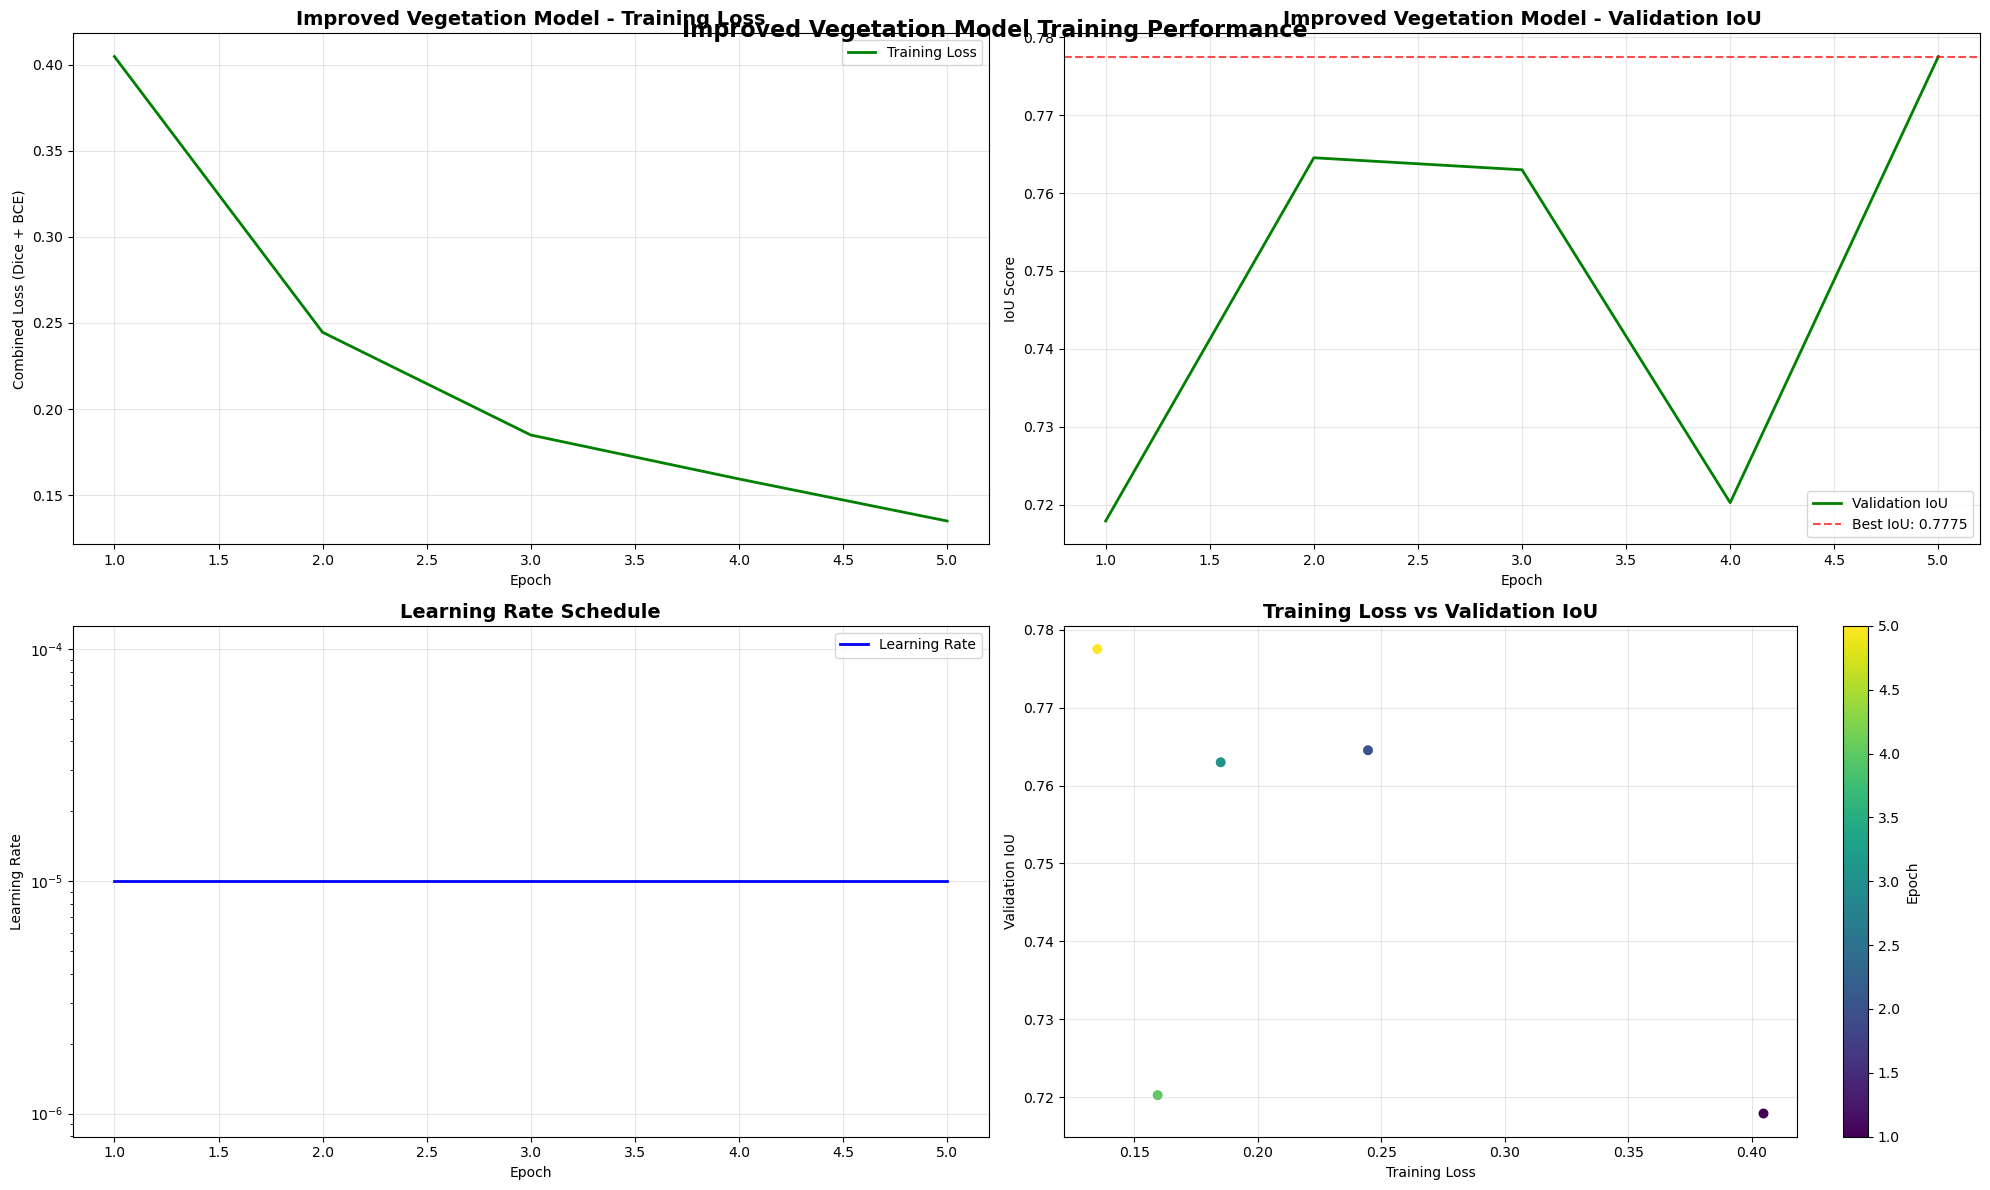


📊 IMPROVED TRAINING SUMMARY
📉 Final Training Loss: 0.1350
🏆 Best Validation IoU: 0.7775
📈 Final Validation IoU: 0.7775
⏱️ Total Epochs: 5
🎯 Final Learning Rate: 1.00e-05
🔄 LR Reductions: 0


In [12]:
def plot_improved_training_history(history):
    """
    Plot training metrics with learning rate scheduling information
    """
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 12))
    
    epochs = range(1, len(history['train_loss']) + 1)
    
    # Training loss
    ax1.plot(epochs, history['train_loss'], 'g-', linewidth=2, label='Training Loss')
    ax1.set_title('Improved Vegetation Model - Training Loss', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Combined Loss (Dice + BCE)')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Validation IoU
    ax2.plot(epochs, history['val_iou'], 'g-', linewidth=2, label='Validation IoU')
    ax2.axhline(y=max(history['val_iou']), color='r', linestyle='--', alpha=0.7, label=f'Best IoU: {max(history["val_iou"]):.4f}')
    ax2.set_title('Improved Vegetation Model - Validation IoU', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('IoU Score')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    # Learning Rate Schedule
    ax3.plot(epochs, history['learning_rates'], 'b-', linewidth=2, label='Learning Rate')
    ax3.set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Epoch')
    ax3.set_ylabel('Learning Rate')
    ax3.set_yscale('log')
    ax3.grid(True, alpha=0.3)
    ax3.legend()
    
    # Loss vs IoU correlation
    ax4.scatter(history['train_loss'], history['val_iou'], alpha=0.6, c=epochs, cmap='viridis')
    ax4.set_title('Training Loss vs Validation IoU', fontsize=14, fontweight='bold')
    ax4.set_xlabel('Training Loss')
    ax4.set_ylabel('Validation IoU')
    ax4.grid(True, alpha=0.3)
    cbar = plt.colorbar(ax4.scatter(history['train_loss'], history['val_iou'], c=epochs, cmap='viridis'), ax=ax4)
    cbar.set_label('Epoch')
    
    plt.tight_layout()
    plt.suptitle('Improved Vegetation Model Training Performance', fontsize=16, fontweight='bold', y=0.98)
    plt.show()
    
    print("\n📊 IMPROVED TRAINING SUMMARY")
    print("="*50)
    print(f"📉 Final Training Loss: {history['train_loss'][-1]:.4f}")
    print(f"🏆 Best Validation IoU: {max(history['val_iou']):.4f}")
    print(f"📈 Final Validation IoU: {history['val_iou'][-1]:.4f}")
    print(f"⏱️ Total Epochs: {len(history['train_loss'])}")
    print(f"🎯 Final Learning Rate: {history['learning_rates'][-1]:.2e}")
    print(f"🔄 LR Reductions: {len([lr for i, lr in enumerate(history['learning_rates'][1:], 1) if lr < history['learning_rates'][i-1]])}")

# Plot improved training history
plot_improved_training_history(training_history)

## 13. Model Prediction Visualization with Improvements


IMPROVED VEGETATION MODEL PREDICTIONS VISUALIZATION


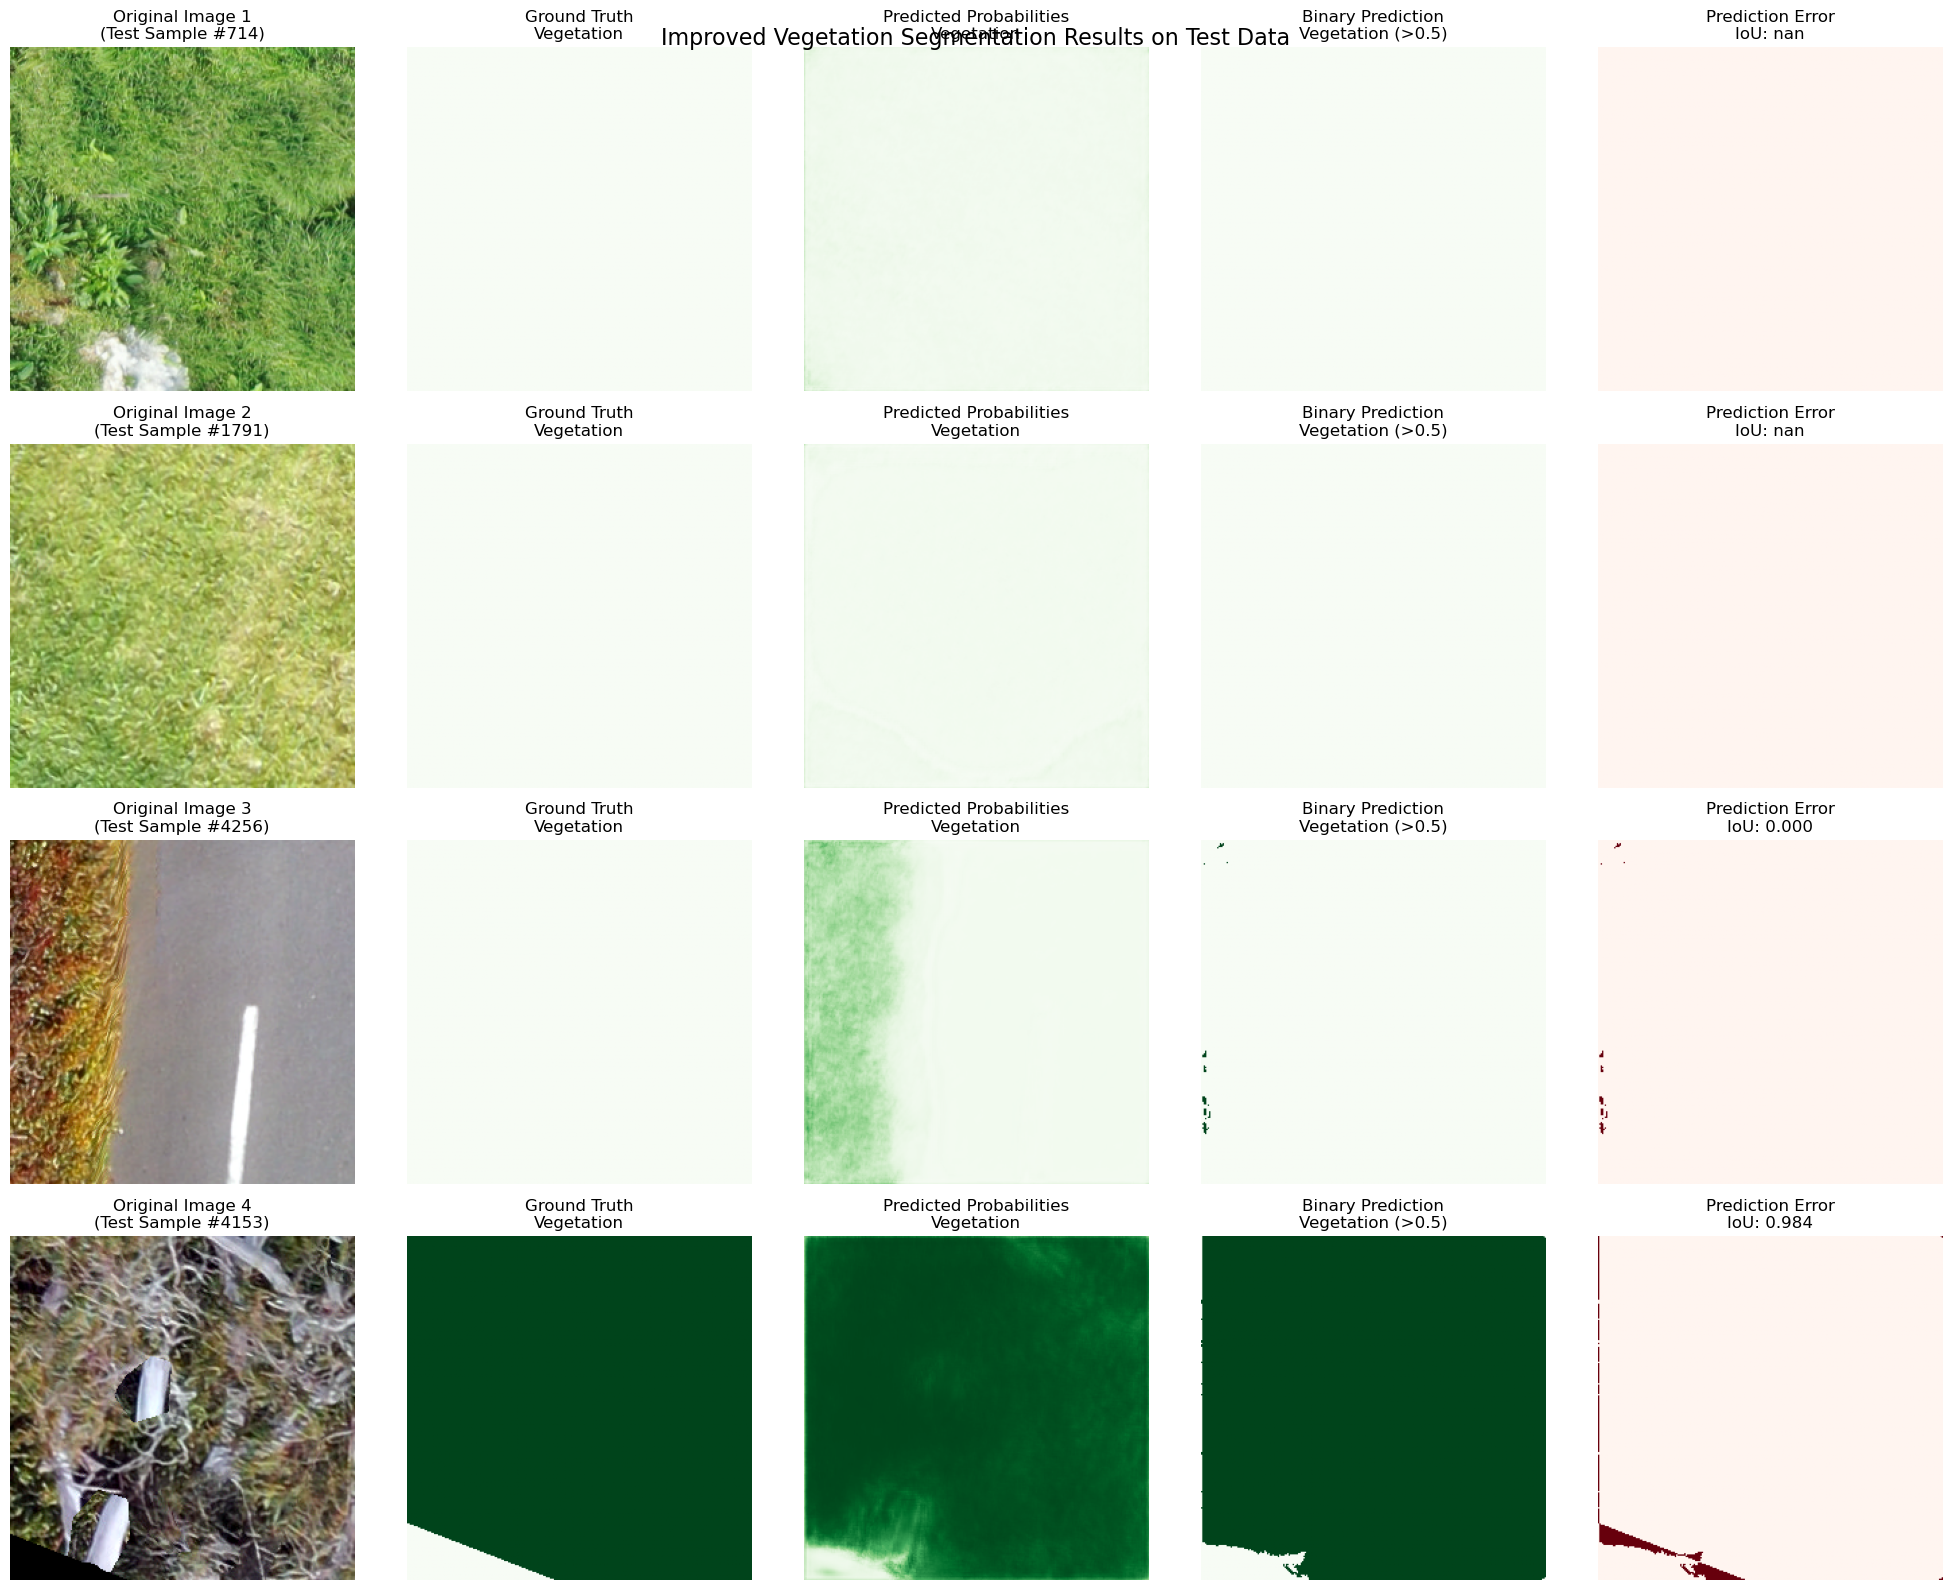

📸 Visualized 4 random improved vegetation segmentation examples
🎲 Random test sample indices: [714, 1791, 4256, 4153]

🎉 Improved vegetation model visualization completed!


In [15]:
import random

def visualize_improved_predictions(model, test_loader, num_samples=4, device="cpu"):
    """
    Visualize improved vegetation model predictions vs ground truth
    """
    model.eval()
    
    # Get all data from the test loader
    all_images = []
    all_masks = []
    
    with torch.no_grad():
        for images, masks in test_loader:
            for i in range(images.shape[0]):
                all_images.append(images[i])
                all_masks.append(masks[i])
    
    # Randomly select samples
    total_samples = len(all_images)
    random_indices = random.sample(range(total_samples), min(num_samples, total_samples))
    
    # Set up the plot
    fig, axes = plt.subplots(num_samples, 5, figsize=(20, 4*num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, -1)
    
    for sample_idx, data_idx in enumerate(random_indices):
        # Get the randomly selected image and mask
        image = all_images[data_idx].to(device).unsqueeze(0)
        mask = all_masks[data_idx].to(device).unsqueeze(0)
        
        # Get predictions
        prediction = model(image)
        prediction_prob = torch.sigmoid(prediction)
        predicted_mask = (prediction_prob > 0.5).float()
        
        # Calculate IoU for this sample
        tp, fp, fn, tn = smp.metrics.get_stats(predicted_mask.long(), mask.long(), mode='binary')
        sample_iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction="micro")
        
        # Convert tensors to numpy for visualization
        image_np = image.squeeze().cpu().detach().permute(1, 2, 0).numpy()
        true_mask_np = mask.squeeze().cpu().detach().numpy()
        pred_mask_np = predicted_mask.squeeze().detach().cpu().numpy()
        prob_mask_np = prediction_prob.squeeze().detach().cpu().numpy()
        
        # Denormalize image for display (ImageNet normalization)
        mean = np.array([0, 0, 0])
        std = np.array([1, 1, 1])
        image_np = image_np * std + mean
        image_np = np.clip(image_np, 0, 1)
        
        # Plot original image
        axes[sample_idx, 0].imshow(image_np)
        axes[sample_idx, 0].set_title(f'Original Image {sample_idx+1}\n(Test Sample #{data_idx})', fontsize=12)
        axes[sample_idx, 0].axis('off')
        
        # Plot ground truth mask
        axes[sample_idx, 1].imshow(true_mask_np, cmap='Greens', vmin=0, vmax=1)
        axes[sample_idx, 1].set_title(f'Ground Truth\nVegetation', fontsize=12)
        axes[sample_idx, 1].axis('off')
        
        # Plot prediction probabilities
        axes[sample_idx, 2].imshow(prob_mask_np, cmap='Greens', vmin=0, vmax=1)
        axes[sample_idx, 2].set_title(f'Predicted Probabilities\nVegetation', fontsize=12)
        axes[sample_idx, 2].axis('off')
        
        # Plot binary prediction
        axes[sample_idx, 3].imshow(pred_mask_np, cmap='Greens', vmin=0, vmax=1)
        axes[sample_idx, 3].set_title(f'Binary Prediction\nVegetation (>0.5)', fontsize=12)
        axes[sample_idx, 3].axis('off')
        
        # Plot difference (error map)
        error_map = np.abs(true_mask_np - pred_mask_np)
        axes[sample_idx, 4].imshow(error_map, cmap='Reds', vmin=0, vmax=1)
        axes[sample_idx, 4].set_title(f'Prediction Error\nIoU: {sample_iou:.3f}', fontsize=12)
        axes[sample_idx, 4].axis('off')
    
    plt.tight_layout()
    plt.suptitle('Improved Vegetation Segmentation Results on Test Data', fontsize=16, y=0.98)
    plt.show()
    
    print(f"📸 Visualized {len(random_indices)} random improved vegetation segmentation examples")
    print(f"🎲 Random test sample indices: {random_indices}")

# Execute improved model visualization
print("\n" + "="*70)
print("IMPROVED VEGETATION MODEL PREDICTIONS VISUALIZATION")
print("="*70)

visualize_improved_predictions(model, test_loader, num_samples=4, device=DEVICE)

print("\n🎉 Improved vegetation model visualization completed!")
print("="*70)